<center><h1>Chien-Ting_Chen_HW4</h1></center>
<br>
<br>

Name: Chien-Ting Chen
<br>
Github Username: jessica91816
<br>
USC ID: 2009118611

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [6]:
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, roc_curve, roc_auc_score)
import statsmodels.api as sm
from sklearn.metrics import accuracy_score, confusion_matrix
import warnings
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score

Get the AReM Data Set

In [8]:
path = 'AReM'

### (b) Splitting Data

In [10]:
activities = ['bending1', 'bending2','cycling', 'lying','sitting','standing', 'walking']
training_file = []
test_file = []

for activity in activities:
    file_path = os.path.join(path, activity)
    if activity in['bending1','bending2']:
        test_name = ['dataset1.csv','dataset2.csv']
    else:
        test_name = ['dataset1.csv','dataset2.csv','dataset3.csv']
    for file in os.listdir(file_path):
        now_file_path = os.path.join(file_path, file)
        if file in test_name:
            test_file.append(now_file_path)
        else:
            training_file.append(now_file_path)
print("Training:", len(training_file))
print("Test:", len(test_file))
print("Total", len(training_file)+len(test_file))

Training: 69
Test: 19
Total 88


### (c) Feature Extraction

In [12]:
column_names=[
            'time',
            'avg_rss12',
            'var_rss12',
            'avg_rss13',
            'var_rss13',
            'avg_rss23',
            'var_rss23'
        ]

allfile = training_file + test_file

def read_clean(file_path):
    df = pd.read_csv(
        file_path,
        skiprows=5,
        header=None,
        names=column_names,
        sep=r',|\s+',
        engine='python',
        usecols=range(7)
    )
    full_time = pd.Index(range(0, 120000, 250), name='time')
    df = (df.set_index('time').reindex(full_time).interpolate(method='linear').reset_index())
    return df

for f in allfile:
    df = read_clean(f)
    if df.shape!=(480,7) or df.isna().sum().sum()> 0:
        print(f, "Shape", df.shape, "Missing", df.isna().sum().sum())

#print(df.head())

def extraction(df):
    feature = {}
    for i in range(1,7):
        series = df.iloc[:,i]
        feature[f'min{i}'] = series.min()
        feature[f'max{i}'] = series.max()
        feature[f'mean{i}'] = series.mean()
        feature[f'median{i}'] = series.median()
        feature[f'std{i}'] = series.std()
        feature[f'1st_quart{i}'] = series.quantile(0.25)
        feature[f'3rd_quart{i}'] = series.quantile(0.75)
    return feature

feature_row = []
for f in allfile:
    df = read_clean(f)
    result = extraction(df)
    feature_row.append(result)
data = pd.DataFrame(feature_row)

data.index = range(1, len(data)+1)
data.index.name = 'Instance'
print(data)



           min1   max1      mean1  median1      std1  1st_quart1  3rd_quart1  \
Instance                                                                       
1         35.00  47.40  43.954500   44.330  1.558835       43.00     45.0000   
2         33.00  47.75  42.179812   43.500  3.670666       39.15     45.0000   
3         33.00  45.75  41.678063   41.750  2.243490       41.33     42.7500   
4         37.00  48.00  43.454958   43.250  1.386098       42.50     45.0000   
5         36.25  48.00  43.969125   44.500  1.618364       43.31     44.6700   
...         ...    ...        ...      ...       ...         ...         ...   
84        35.50  46.25  43.174938   43.670  1.989052       42.50     44.5000   
85        32.75  47.00  42.760562   44.500  3.398919       41.33     45.3725   
86        19.33  43.50  34.227771   35.500  4.889576       30.50     37.7500   
87        12.50  45.00  33.509729   34.125  4.850923       30.50     36.7500   
88        15.00  46.75  34.660583   35.0

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

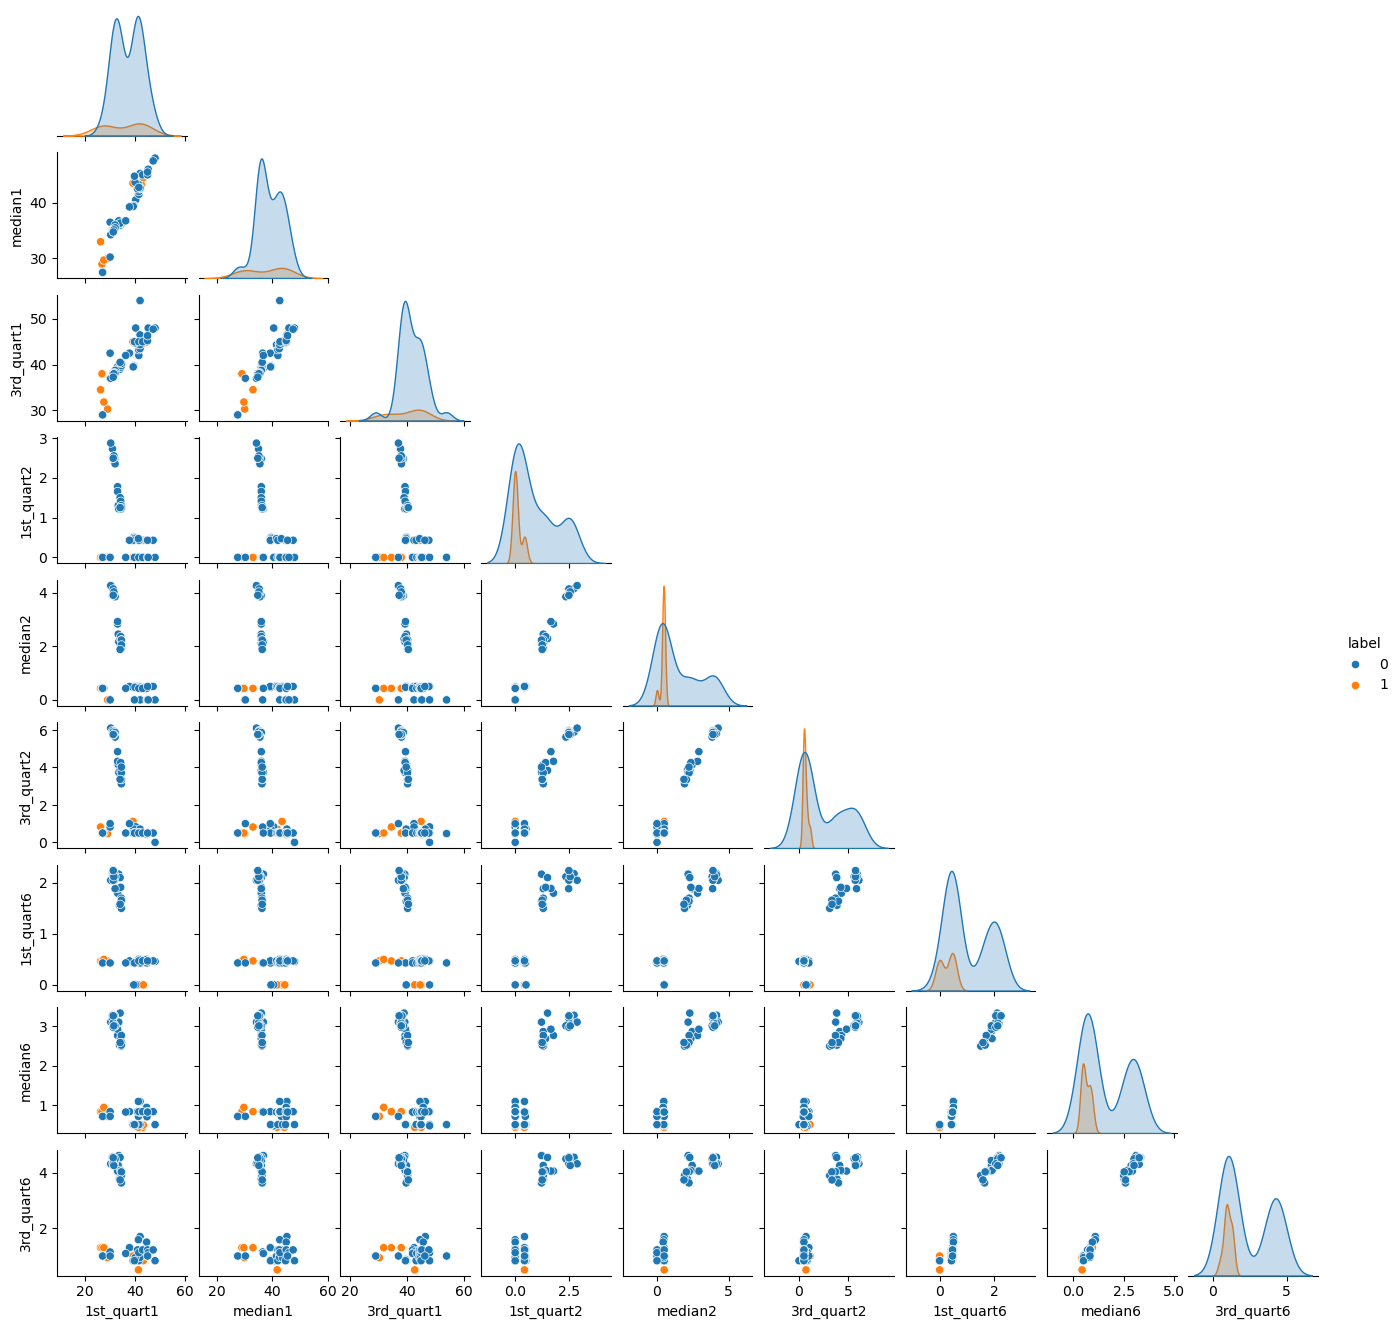

In [16]:
training_data = data.iloc[:len(training_file)].copy()
activity = os.path.basename(os.path.dirname(training_file[0]))

training_label = []
for f in training_file:
    activity = os.path.basename(os.path.dirname(f))
    if activity in ['bending1', 'bending2']:
        training_label.append(1)
    else:
        training_label.append(0)
training_data['label'] = training_label
training_data.columns
series1 = ['1st_quart1', 'median1', '3rd_quart1']
series2 = ['1st_quart2', 'median2', '3rd_quart2']
series6 = ['1st_quart6', 'median6', '3rd_quart6']
selected_columns = series1 + series2 + series6
plot_data = training_data[['label'] + selected_columns].copy()
sns.pairplot(data=plot_data, hue='label', corner=True, height=1.5)

#### ii. Splitted Plots

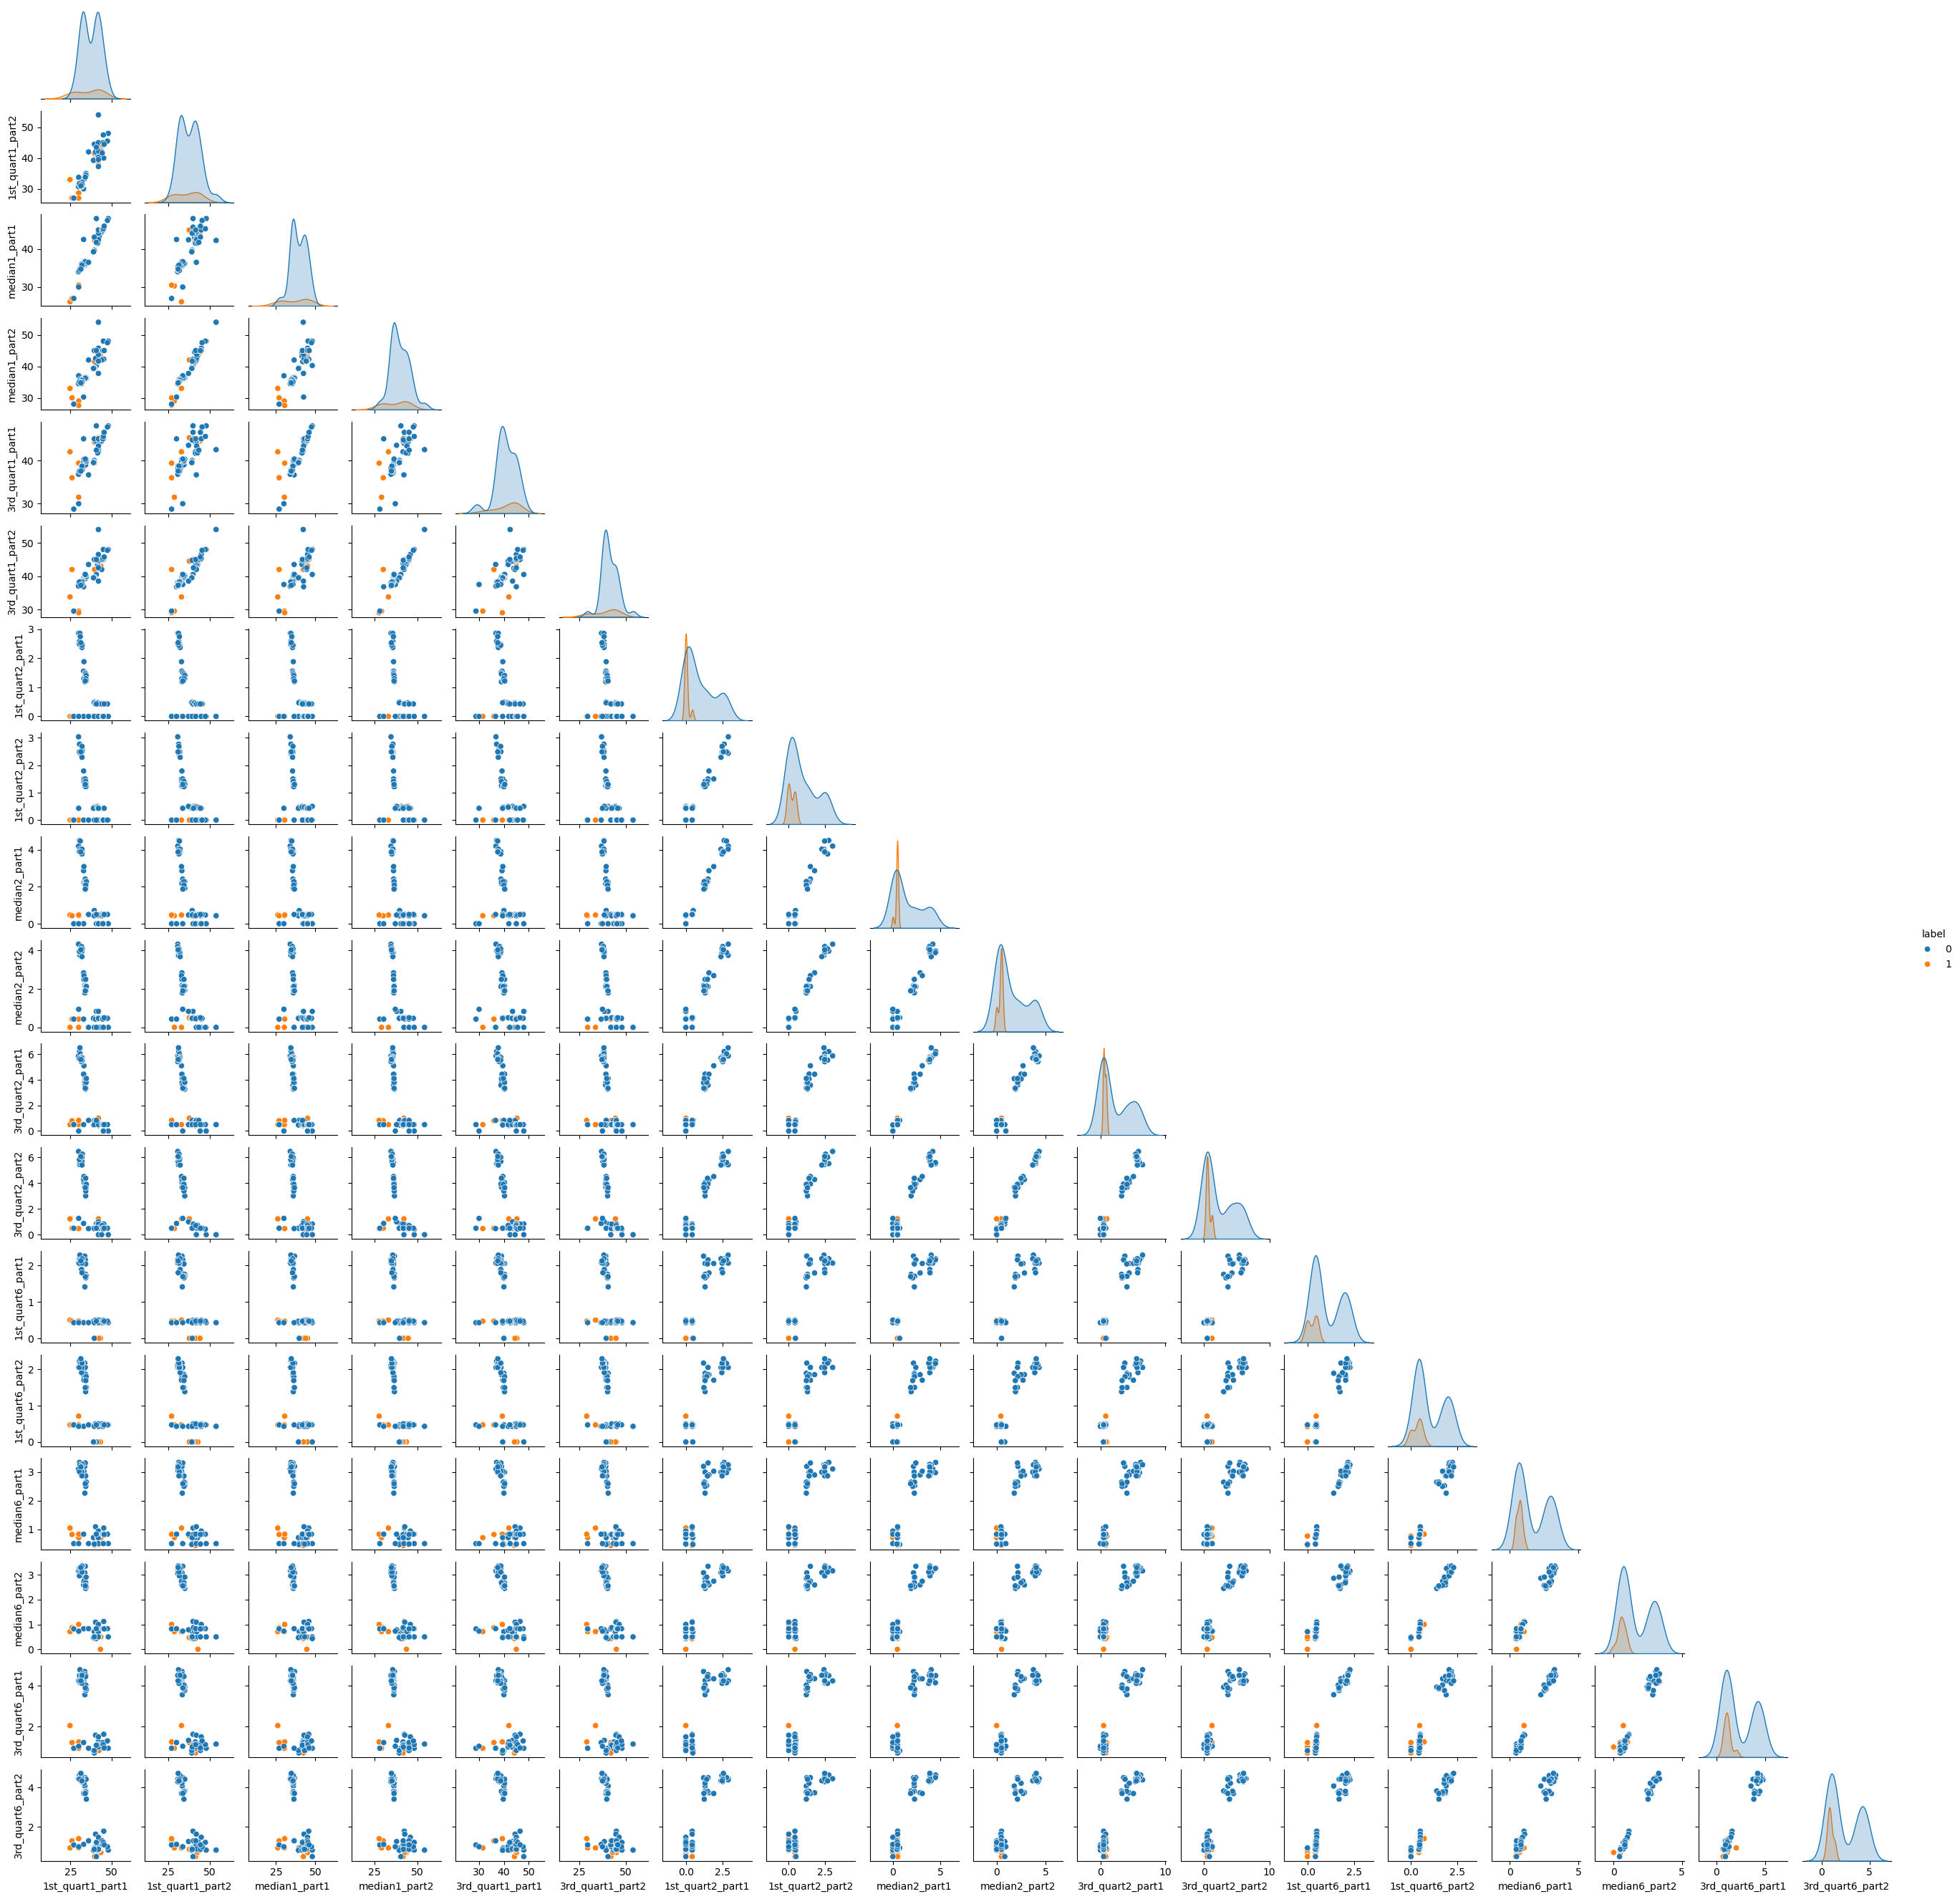

In [18]:
split_row = []
for i in training_file:
    df = read_clean(i)
    part1 = df.iloc[:240]
    part2 = df.iloc[240:]
    result1 = extraction(part1)
    result2 = extraction(part2)
    split_result = {}
    for column in selected_columns:
        split_result[f'{column}_part1'] = result1[column]
        split_result[f'{column}_part2'] = result2[column]
    split_row.append(split_result)
split_data = pd.DataFrame(split_row)
split_plot = split_data.copy()
split_plot['label'] = training_label
sns.pairplot(data=split_plot, hue='label', corner=True, height=1.5)

After dividing each time series into two parts, I observed that part 1 and 2 of each time series looked similar, which means that the statistical features of the two parts were close. Although the split data provided more detailed temporal information, there was still considerable overlap between bending and other activities. Therefore, the difference from 2(a)(i) was not considerable.

#### iii. Time Series Segments

In [21]:
training_dfs = [read_clean(f) for f in training_file]

X_by_l = {}

for l in range(1, 21):
    feature_row = []

    for df in training_dfs:
        groups = np.array_split(np.arange(len(df)), l)
        instance_feature = {}

        for part_num, rows in enumerate(groups, start=1):
            part = df.iloc[rows]
            result = extraction(part)

            for feature_name, value in result.items():
                new_name = f'{feature_name}_part{part_num}'
                instance_feature[new_name] = value

        feature_row.append(instance_feature)
    X_by_l[l] = pd.DataFrame(feature_row)

y = np.array(training_label)

In [22]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

all_results = []
models_by_l = {}

for l in range(1, 21):
    X = X_by_l[l]
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('logistic', LogisticRegression(
            C=1e6,
            #solver='liblinear',
            max_iter=2000,
            random_state=42
        ))])

    rfecv = RFECV(
        estimator=model,
        step=1,
        cv=skf,
        scoring='accuracy',
        min_features_to_select=1,
        importance_getter='named_steps.logistic.coef_',
        n_jobs=-1
    )

    rfecv.fit(X, y)
    best_score = rfecv.cv_results_['mean_test_score'].max()
    all_results.append({
        'l': l,
        'p': rfecv.n_features_,
        'CV Accuracy': best_score
    })
    models_by_l[l] = rfecv
    print(
        f'l = {l}, '
        f'p = {rfecv.n_features_}, '
        f'CV Accuracy = {best_score:.3f}')

l = 1, p = 16, CV Accuracy = 0.986
l = 2, p = 6, CV Accuracy = 0.971
l = 3, p = 6, CV Accuracy = 0.943
l = 4, p = 9, CV Accuracy = 0.957
l = 5, p = 1, CV Accuracy = 0.957
l = 6, p = 5, CV Accuracy = 0.957
l = 7, p = 8, CV Accuracy = 0.957
l = 8, p = 2, CV Accuracy = 0.971
l = 9, p = 10, CV Accuracy = 0.943
l = 10, p = 8, CV Accuracy = 0.971
l = 11, p = 5, CV Accuracy = 0.957
l = 12, p = 1, CV Accuracy = 0.957
l = 13, p = 11, CV Accuracy = 0.943
l = 14, p = 3, CV Accuracy = 0.957
l = 15, p = 2, CV Accuracy = 0.957
l = 16, p = 8, CV Accuracy = 0.943
l = 17, p = 5, CV Accuracy = 0.971
l = 18, p = 3, CV Accuracy = 0.957
l = 19, p = 2, CV Accuracy = 0.971
l = 20, p = 5, CV Accuracy = 0.971


In [23]:
results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    by=['CV Accuracy', 'p', 'l'],
    ascending=[False, True, True]
).reset_index(drop=True)

best_l = int(results_df.loc[0, 'l'])
best_p = int(results_df.loc[0, 'p'])
best_accuracy = results_df.loc[0, 'CV Accuracy']

best_model = models_by_l[best_l]

print("Best l:", best_l)
print("Best p:", best_p)
print("Best CV Accuracy:", best_accuracy)

results_df

Best l: 1
Best p: 16
Best CV Accuracy: 0.9857142857142858


,l,p,CV Accuracy
0,1,16,0.985714
1,8,2,0.971429
2,19,2,0.971429
3,17,5,0.971429
4,20,5,0.971429
5,2,6,0.971429
6,10,8,0.971429
7,5,1,0.957143
8,12,1,0.957143
9,15,2,0.957143


The right way to perform cross-validation is to split the data into training and validation folds. RFE should select features using only each training fold, and the resulting model should then be evaluated on the corresponding validation fold. If RFE is performed on all 69 instances before cross-validation, the validation labels will influence feature selection, causing data leakage and potentially overestimating the model's performance. Also, there are only 9 bending instances compared with 60 other instances, so StratifiedKFold helps maintain approximately the same class proportions in each fold. Standardization should also be fitted using only each training fold and then applied to the corresponding validation fold.

#### iv. Confusion Matrix

In [26]:
X_train_fin = X_by_l[best_l]
y_train_fin = np.array(training_label)
final_rfe = models_by_l[best_l]
print("Selected features:", final_rfe.n_features_)

y_train_pred = final_rfe.predict(X_train_fin)
cm = confusion_matrix(y_train_fin, y_train_pred)
print(cm)

y_train_prob = final_rfe.predict_proba(X_train_fin)[:, 1]
fpr, tpr, thresholds = roc_curve(y_train_fin, y_train_prob)
train_auc = roc_auc_score(y_train_fin, y_train_prob)

Selected features: 16
[[60  0]
 [ 0  9]]


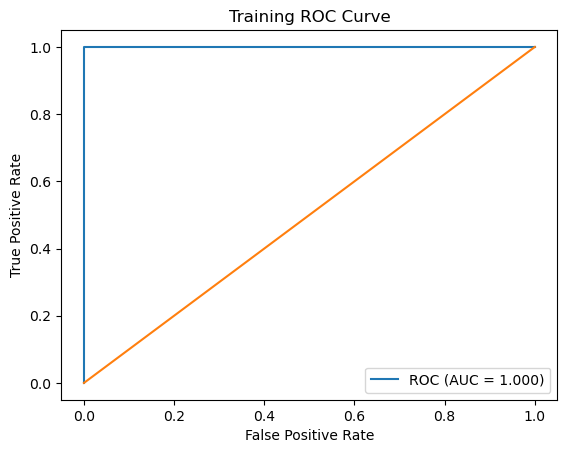

In [27]:
plt.plot(fpr, tpr, label=f'ROC (AUC = {train_auc:.3f})')
plt.plot([0,1], [0,1])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Training ROC Curve')
plt.legend()
plt.show()

In [28]:
selected_features = X_train_fin.columns[final_rfe.support_]
model = final_rfe.estimator_.named_steps['logistic']
scaler = final_rfe.estimator_.named_steps['scaler']
print('Intercept:', model.intercept_[0])

coefficient_table = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient': model.coef_[0]
})
print(coefficient_table)

X_selected = X_train_fin.loc[:, selected_features]
X_scaled = pd.DataFrame(
    scaler.transform(X_selected.to_numpy()),
    columns=selected_features,
    index=X_selected.index
)

X_sm = sm.add_constant(X_scaled, has_constant='add')
logit_result = sm.Logit(y_train_fin, X_sm).fit(method='bfgs', maxiter=1000, disp=False)
print(logit_result.summary())

Intercept: -10.972779510074217
             Feature  Coefficient
0         min1_part1    -1.937793
1         max1_part1     1.709278
2        mean1_part1    -1.239359
3   3rd_quart1_part1    -2.925989
4         max2_part1    -2.048019
5         max3_part1     0.751190
6   3rd_quart3_part1    -2.292143
7         max4_part1     2.173464
8      median4_part1    -1.155283
9   1st_quart4_part1    -1.274557
10        min5_part1     4.503284
11        max5_part1     4.074208
12       mean5_part1     1.630801
13  1st_quart5_part1     1.080144
14        std6_part1    -1.275809
15  1st_quart6_part1    -1.946522
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       52
Method:                           MLE   Df Model:                           16
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:                   1.

#### v. Test Classifier

In [30]:
test_feature_row = []
test_label = []

for f in test_file:
    df = read_clean(f)
    groups = np.array_split(np.arange(len(df)), best_l)
    instance_feature = {}

    for part_num, rows in enumerate(groups, start=1):
        result = extraction(df.iloc[rows])

        for feature_name, value in result.items():
            new_name = f'{feature_name}_part{part_num}'
            instance_feature[new_name] = value

    test_feature_row.append(instance_feature)

    activity = os.path.basename(os.path.dirname(f))
    test_label.append(1 if activity in ['bending1', 'bending2'] else 0)

X_test_fin = pd.DataFrame(test_feature_row)

X_test_fin = X_test_fin.loc[:, X_train_fin.columns]
y_test_fin = np.array(test_label)
y_test_pred = final_rfe.predict(X_test_fin)
test_accuracy = accuracy_score(y_test_fin, y_test_pred)
best_cv_accuracy = final_rfe.cv_results_['mean_test_score'].max()

print(f"CV Accuracy: {best_cv_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print("Test Confusion Matrix:")
print(confusion_matrix(y_test_fin, y_test_pred))

CV Accuracy: 0.9857
Test Accuracy: 1.0000
Test Confusion Matrix:
[[15  0]
 [ 0  4]]


#### vi. Separation

Yes, the classes appear well separated in the selected feature space. The statsmodels output showed a possible quasi-separation problem and very large standard errors. These suggest that the logistic regression coefficients are unstable, so the p-values cannot be reliably interpreted.

#### vii. Imbalance

The training set is imbalanced, with 9 bending instances and 60 instances of other activities.

In [35]:
rng = np.random.default_rng(42)
bending_index = np.where(y_train_fin == 1)[0]
other_index = np.where(y_train_fin == 0)[0]

sampled_other_index = rng.choice(
    other_index,
    size=len(bending_index),
    replace=False
)

sampled_index = np.concatenate([bending_index, sampled_other_index])

features_cc = X_train_fin.columns[final_rfe.support_]
X_cc = X_train_fin.iloc[sampled_index].loc[:, features_cc]
y_cc = y_train_fin[sampled_index]

cc_model = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(C=1e6, max_iter=2000))
])

cc_model.fit(X_cc, y_cc)
original_ratio = y_train_fin.mean()
sampled_ratio = y_cc.mean()
adjustment = (
    np.log(original_ratio / (1 - original_ratio))
    - np.log(sampled_ratio / (1 - sampled_ratio))
)

cc_model.named_steps['logistic'].intercept_ += adjustment

Test Confusion Matrix:
[[15  0]
 [ 0  4]]
Test AUC: 1.0000


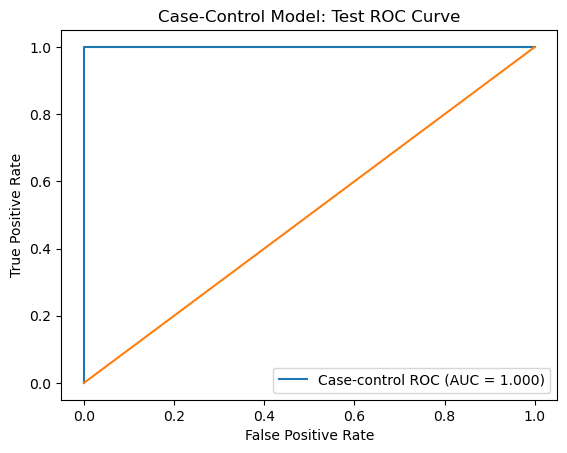

In [36]:
X_test_cc = X_test_fin.loc[:, features_cc]
y_cc_pred = cc_model.predict(X_test_cc)
y_cc_prob = cc_model.predict_proba(X_test_cc)[:, 1]

print("Test Confusion Matrix:")
print(confusion_matrix(y_test_fin, y_cc_pred))

cc_auc = roc_auc_score(y_test_fin, y_cc_prob)
print(f"Test AUC: {cc_auc:.4f}")

fpr, tpr, thresholds = roc_curve(y_test_fin, y_cc_prob)

plt.plot(fpr, tpr, label=f'Case-control ROC (AUC = {cc_auc:.3f})')
plt.plot([0, 1], [0, 1])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Case-Control Model: Test ROC Curve')
plt.legend()
plt.show()

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [39]:
C_values = np.logspace(-4, 4, 20)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

l1_results = []
l1_models = {}

for l in range(1, 21):
    X = X_by_l[l]

    model = Pipeline([
        ('scaler', StandardScaler()),
        ('logistic', LogisticRegression(
            penalty='l1',
            solver='liblinear',
            max_iter=2000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        estimator=model,
        param_grid={'logistic__C': C_values},
        cv=skf,
        scoring='accuracy',
        n_jobs=-1
    )

    search.fit(X, y_train_fin)
    coefficients = search.best_estimator_.named_steps['logistic'].coef_[0]
    selected_count = np.count_nonzero(coefficients)

    l1_results.append({
        'l': l,
        'Best C': search.best_params_['logistic__C'],
        'CV Accuracy': search.best_score_,
        'Selected Features': selected_count
    })
    l1_models[l] = search.best_estimator_

    print(
        f'l = {l}, '
        f'C = {search.best_params_["logistic__C"]:.4f}, '
        f'CV Accuracy = {search.best_score_:.4f}, '
        f'Selected Features = {selected_count}'
    )

l = 1, C = 3792.6902, CV Accuracy = 0.9857, Selected Features = 28
l = 2, C = 11.2884, CV Accuracy = 0.9571, Selected Features = 11
l = 3, C = 0.2336, CV Accuracy = 0.9571, Selected Features = 5
l = 4, C = 545.5595, CV Accuracy = 0.9571, Selected Features = 35
l = 5, C = 29.7635, CV Accuracy = 0.9418, Selected Features = 18
l = 6, C = 11.2884, CV Accuracy = 0.9571, Selected Features = 17
l = 7, C = 78.4760, CV Accuracy = 0.9560, Selected Features = 26
l = 8, C = 29.7635, CV Accuracy = 0.9429, Selected Features = 22
l = 9, C = 10000.0000, CV Accuracy = 0.9429, Selected Features = 273
l = 10, C = 78.4760, CV Accuracy = 0.9714, Selected Features = 28
l = 11, C = 1.6238, CV Accuracy = 0.9571, Selected Features = 9
l = 12, C = 0.6158, CV Accuracy = 0.9714, Selected Features = 7
l = 13, C = 0.6158, CV Accuracy = 0.9571, Selected Features = 10
l = 14, C = 1.6238, CV Accuracy = 0.9571, Selected Features = 12
l = 15, C = 545.5595, CV Accuracy = 0.9429, Selected Features = 88
l = 16, C = 78.4760

In [40]:
l1_results_df = pd.DataFrame(l1_results)

l1_results_df = l1_results_df.sort_values(
    by=['CV Accuracy', 'Selected Features', 'l'],
    ascending=[False, True, True]
).reset_index(drop=True)

best_l_l1 = int(l1_results_df.loc[0, 'l'])
best_C_l1 = l1_results_df.loc[0, 'Best C']
best_cv_accuracy_l1 = l1_results_df.loc[0, 'CV Accuracy']

best_model_l1 = l1_models[best_l_l1]

print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print("Best CV Accuracy:", best_cv_accuracy_l1)

l1_results_df

Best l: 1
Best C: 3792.690190732246
Best CV Accuracy: 0.9857142857142858


,l,Best C,CV Accuracy,Selected Features
0,1,3792.690191,0.985714,28
1,12,0.615848,0.971429,7
2,10,78.475997,0.971429,28
3,20,78.475997,0.971429,44
4,2,11.288379,0.957143,11
5,3,0.233572,0.957143,5
6,18,0.615848,0.957143,7
7,11,1.623777,0.957143,9
8,13,0.615848,0.957143,10
9,19,1.623777,0.957143,10


#### ii. Comparison

The L1-penalized model and the RFE model both have a 5-fold cross-validation accuracy of 98.57%. RFE selected 16 features, while L1 retained 28 features. Thus, RFE achieved the same CV accuracy with fewer features. However, L1 is easier to implement because it selects features during training. RFE needs to repeatedly remove features and refit the model.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [45]:
training_activity = np.array([
    os.path.basename(os.path.dirname(f))
    for f in training_file
])

test_activity = np.array([
    os.path.basename(os.path.dirname(f))
    for f in test_file
])

print("Training class counts:")
print(pd.Series(training_activity).value_counts())

Training class counts:
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64


In [46]:
warnings.filterwarnings(
    'ignore',
    message=r'The least populated class in y has only 4 members, which is less than n_splits=5\.',
    category=UserWarning
)
multiclass_results = []
multiclass_models = {}

skf_multi = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for l in range(1, 21):
    X = X_by_l[l]
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('logistic', LogisticRegression(
            penalty='l1',
            solver='saga',
            max_iter=10000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        estimator=model,
        param_grid={'logistic__C': C_values},
        cv=skf_multi,
        scoring='accuracy',
        n_jobs=-1
    )
    search.fit(X, training_activity)

    multiclass_results.append({
        'l': l,
        'Best C': search.best_params_['logistic__C'],
        'CV Accuracy': search.best_score_
    })

    multiclass_models[l] = search.best_estimator_

    print(
        f'l = {l}, '
        f'C = {search.best_params_["logistic__C"]:.4f}, '
        f'CV Accuracy = {search.best_score_:.4f}'
    )

l = 1, C = 4.2813, CV Accuracy = 0.9132
l = 2, C = 1.6238, CV Accuracy = 0.9143
l = 3, C = 4.2813, CV Accuracy = 0.8275
l = 4, C = 10000.0000, CV Accuracy = 0.8846
l = 5, C = 78.4760, CV Accuracy = 0.8703
l = 6, C = 206.9138, CV Accuracy = 0.8560
l = 7, C = 206.9138, CV Accuracy = 0.8418
l = 8, C = 78.4760, CV Accuracy = 0.8560
l = 9, C = 1.6238, CV Accuracy = 0.8560
l = 10, C = 78.4760, CV Accuracy = 0.8264
l = 11, C = 78.4760, CV Accuracy = 0.7989
l = 12, C = 206.9138, CV Accuracy = 0.8110
l = 13, C = 1438.4499, CV Accuracy = 0.7978
l = 14, C = 29.7635, CV Accuracy = 0.7835
l = 15, C = 206.9138, CV Accuracy = 0.8264
l = 16, C = 0.2336, CV Accuracy = 0.7824
l = 17, C = 4.2813, CV Accuracy = 0.8275
l = 18, C = 78.4760, CV Accuracy = 0.8703
l = 19, C = 0.2336, CV Accuracy = 0.8121
l = 20, C = 4.2813, CV Accuracy = 0.8121


In [47]:
multiclass_results_df = pd.DataFrame(multiclass_results)

multiclass_results_df = multiclass_results_df.sort_values(
    by=['CV Accuracy', 'l', 'Best C'],
    ascending=[False, True, True]
).reset_index(drop=True)

best_l_multi = int(multiclass_results_df.loc[0, 'l'])
best_C_multi = multiclass_results_df.loc[0, 'Best C']
best_cv_accuracy_multi = multiclass_results_df.loc[0, 'CV Accuracy']

best_model_multi = multiclass_models[best_l_multi]

print("Best l:", best_l_multi)
print("Best C:", best_C_multi)
print("Best CV Accuracy:", best_cv_accuracy_multi)

multiclass_results_df

Best l: 2
Best C: 1.623776739188721
Best CV Accuracy: 0.9142857142857143


,l,Best C,CV Accuracy
0,2,1.623777,0.914286
1,1,4.281332,0.913187
2,4,10000.000000,0.884615
3,5,78.475997,0.870330
4,18,78.475997,0.870330
5,6,206.913808,0.856044
6,8,78.475997,0.856044
7,9,1.623777,0.856044
8,7,206.913808,0.841758
9,3,4.281332,0.827473


Test Accuracy: 0.8421
Test Error: 0.1579


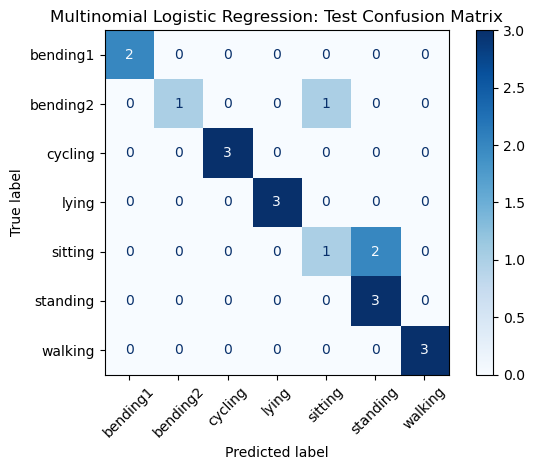

In [48]:
test_rows_multi = []

for f in test_file:
    df = read_clean(f)
    groups = np.array_split(np.arange(len(df)), best_l_multi)
    instance_feature = {}

    for part_num, rows in enumerate(groups, start=1):
        result = extraction(df.iloc[rows])

        for feature_name, value in result.items():
            new_name = f'{feature_name}_part{part_num}'
            instance_feature[new_name] = value

    test_rows_multi.append(instance_feature)

X_test_multi = pd.DataFrame(test_rows_multi)
X_test_multi = X_test_multi.loc[:, X_by_l[best_l_multi].columns]
y_pred_multi = best_model_multi.predict(X_test_multi)

test_accuracy_multi = accuracy_score(test_activity, y_pred_multi)
test_error_multi = 1 - test_accuracy_multi

print(f"Test Accuracy: {test_accuracy_multi:.4f}")
print(f"Test Error: {test_error_multi:.4f}")

ConfusionMatrixDisplay.from_predictions(
    test_activity,
    y_pred_multi,
    labels=best_model_multi.classes_,
    cmap='Blues',
    xticks_rotation=45
)
plt.title('Multinomial Logistic Regression: Test Confusion Matrix')
plt.tight_layout()
plt.show()

Confusion matrix rows represent the true classes and columns represent the predicted classes, while each ROC curve treats one activity as positive and all other activities as negative (one-vs-rest).

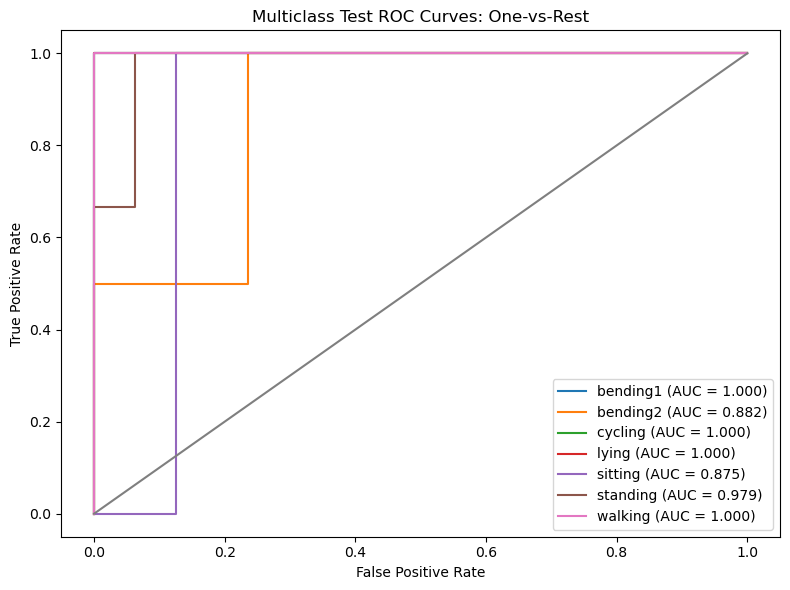

Activity      AUC
bending1 1.000000
bending2 0.882353
 cycling 1.000000
   lying 1.000000
 sitting 0.875000
standing 0.979167
 walking 1.000000
Macro-average AUC: 0.9624


In [50]:
y_prob_multi = best_model_multi.predict_proba(X_test_multi)
classes = best_model_multi.classes_

auc_results = []

plt.figure(figsize=(8, 6))

for i, activity in enumerate(classes):
    y_binary = (test_activity == activity).astype(int)

    fpr, tpr, thresholds = roc_curve(
        y_binary,
        y_prob_multi[:, i]
    )

    activity_auc = roc_auc_score(y_binary, y_prob_multi[:, i])
    auc_results.append({
        'Activity': activity,
        'AUC': activity_auc
    })
    plt.plot(
        fpr, tpr,
        label=f'{activity} (AUC = {activity_auc:.3f})'
    )

plt.plot([0, 1], [0, 1])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass Test ROC Curves: One-vs-Rest')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

auc_table = pd.DataFrame(auc_results)
print(auc_table.to_string(index=False))
print(f"Macro-average AUC: {auc_table['AUC'].mean():.4f}")

#### ii. Naive Bayes

In [52]:
nb_results = []
for l in range(1, 21):
    X = X_by_l[l]

    gaussian_scores = cross_val_score(
        GaussianNB(),
        X,
        training_activity,
        cv=skf_multi,
        scoring='accuracy'
    )

    multinomial_scores = cross_val_score(
        MultinomialNB(),
        X,
        training_activity,
        cv=skf_multi,
        scoring='accuracy'
    )

    nb_results.append({
        'l': l,
        'Gaussian CV Accuracy': gaussian_scores.mean(),
        'Multinomial CV Accuracy': multinomial_scores.mean()
    })

    print(
        f'l = {l}, '
        f'Gaussian = {gaussian_scores.mean():.4f}, '
        f'Multinomial = {multinomial_scores.mean():.4f}'
    )

l = 1, Gaussian = 0.8571, Multinomial = 0.8549
l = 2, Gaussian = 0.8275, Multinomial = 0.7956
l = 3, Gaussian = 0.6813, Multinomial = 0.7967
l = 4, Gaussian = 0.7253, Multinomial = 0.7824
l = 5, Gaussian = 0.6527, Multinomial = 0.8121
l = 6, Gaussian = 0.6527, Multinomial = 0.7835
l = 7, Gaussian = 0.6956, Multinomial = 0.7835
l = 8, Gaussian = 0.6670, Multinomial = 0.7824
l = 9, Gaussian = 0.6385, Multinomial = 0.7835
l = 10, Gaussian = 0.6813, Multinomial = 0.7835
l = 11, Gaussian = 0.6824, Multinomial = 0.7824
l = 12, Gaussian = 0.5945, Multinomial = 0.7670
l = 13, Gaussian = 0.6110, Multinomial = 0.7967
l = 14, Gaussian = 0.5538, Multinomial = 0.7670
l = 15, Gaussian = 0.5659, Multinomial = 0.7681
l = 16, Gaussian = 0.5538, Multinomial = 0.7824
l = 17, Gaussian = 0.5670, Multinomial = 0.7670
l = 18, Gaussian = 0.4802, Multinomial = 0.7824
l = 19, Gaussian = 0.5385, Multinomial = 0.7527
l = 20, Gaussian = 0.5516, Multinomial = 0.7670


In [53]:
nb_results_df = pd.DataFrame(nb_results)
gaussian_best_idx = nb_results_df['Gaussian CV Accuracy'].idxmax()
multinomial_best_idx = nb_results_df['Multinomial CV Accuracy'].idxmax()

best_l_gaussian = int(nb_results_df.loc[gaussian_best_idx, 'l'])
best_l_multinomial = int(nb_results_df.loc[multinomial_best_idx, 'l'])

best_cv_gaussian = nb_results_df.loc[
    gaussian_best_idx, 'Gaussian CV Accuracy'
]
best_cv_multinomial = nb_results_df.loc[
    multinomial_best_idx, 'Multinomial CV Accuracy'
]

print("Gaussian best l:", best_l_gaussian)
print("Gaussian best CV accuracy:", best_cv_gaussian)
print("Multinomial best l:", best_l_multinomial)
print("Multinomial best CV accuracy:", best_cv_multinomial)
nb_results_df

Gaussian best l: 1
Gaussian best CV accuracy: 0.8571428571428573
Multinomial best l: 1
Multinomial best CV accuracy: 0.8549450549450549


,l,Gaussian CV Accuracy,Multinomial CV Accuracy
0,1,0.857143,0.854945
1,2,0.827473,0.795604
2,3,0.681319,0.796703
3,4,0.725275,0.782418
4,5,0.652747,0.812088
5,6,0.652747,0.783516
6,7,0.695604,0.783516
7,8,0.667033,0.782418
8,9,0.638462,0.783516
9,10,0.681319,0.783516


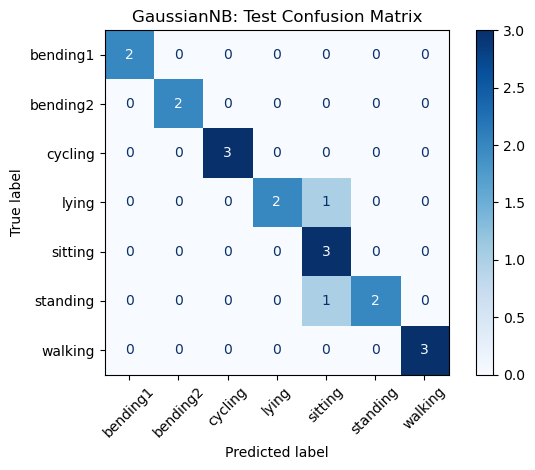

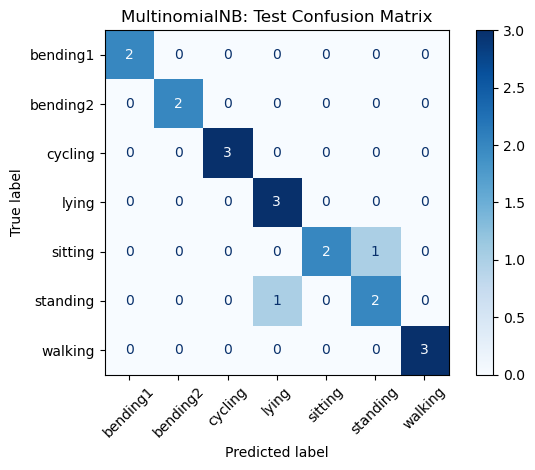

        Model  Test Accuracy  Test Error
   GaussianNB       0.894737    0.105263
MultinomialNB       0.894737    0.105263


In [54]:
test_rows_nb = []
for f in test_file:
    result = extraction(read_clean(f))
    instance_feature = {
        f'{name}_part1': value
        for name, value in result.items()
    }

    test_rows_nb.append(instance_feature)

X_test_nb = pd.DataFrame(test_rows_nb)
X_test_nb = X_test_nb.loc[:, X_by_l[1].columns]
gaussian_model = GaussianNB()
gaussian_model.fit(X_by_l[best_l_gaussian], training_activity)
multinomial_model = MultinomialNB()
multinomial_model.fit(X_by_l[best_l_multinomial], training_activity)

nb_models = {
    'GaussianNB': gaussian_model,
    'MultinomialNB': multinomial_model
}

nb_test_results = []
for name, model in nb_models.items():
    predictions = model.predict(X_test_nb)
    accuracy = accuracy_score(test_activity, predictions)
    nb_test_results.append({
        'Model': name,
        'Test Accuracy': accuracy,
        'Test Error': 1 - accuracy
    })
    ConfusionMatrixDisplay.from_predictions(
        test_activity,
        predictions,
        labels=model.classes_,
        cmap='Blues',
        xticks_rotation=45
    )
    plt.title(f'{name}: Test Confusion Matrix')
    plt.tight_layout()
    plt.show()
nb_test_results_df = pd.DataFrame(nb_test_results)
print(nb_test_results_df.to_string(index=False))

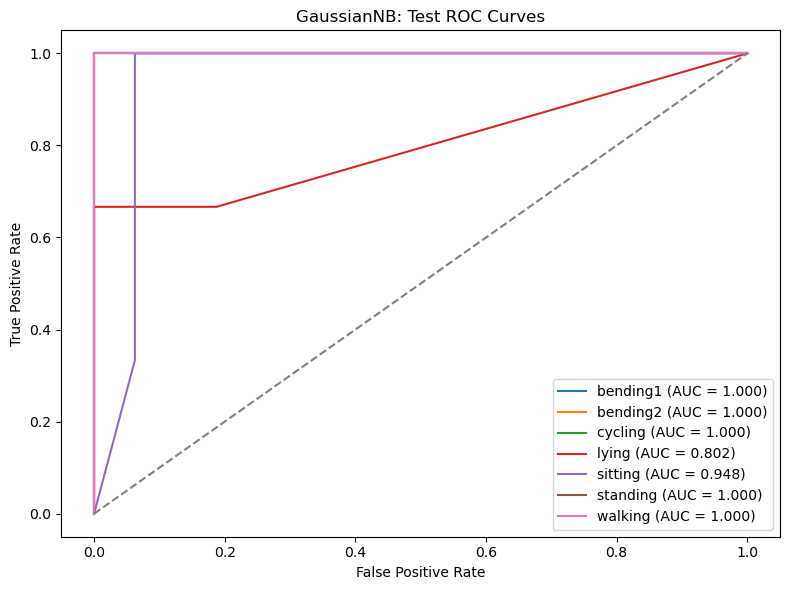

GaussianNB Macro-average AUC: 0.9643


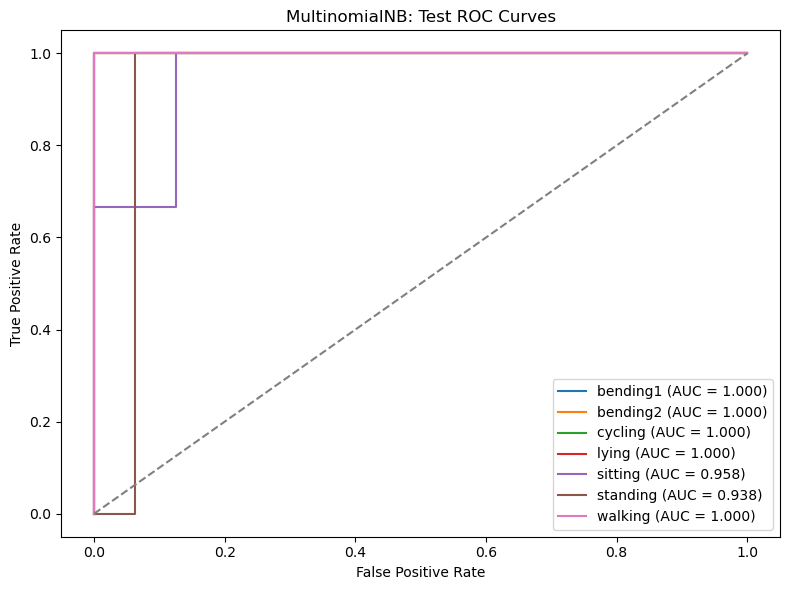

MultinomialNB Macro-average AUC: 0.9851


In [55]:
nb_macro_auc = {}
for name, model in nb_models.items():
    probabilities = model.predict_proba(X_test_nb)
    class_aucs = []
    plt.figure(figsize=(8, 6))
    for i, activity in enumerate(model.classes_):
        y_binary = (test_activity == activity).astype(int)

        fpr, tpr, thresholds = roc_curve(
            y_binary,
            probabilities[:, i]
        )

        activity_auc = roc_auc_score(
            y_binary,
            probabilities[:, i]
        )
        class_aucs.append(activity_auc)

        plt.plot(
            fpr, tpr,
            label=f'{activity} (AUC = {activity_auc:.3f})'
        )

    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{name}: Test ROC Curves')
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()
    nb_macro_auc[name] = np.mean(class_aucs)
    print(f'{name} Macro-average AUC: {nb_macro_auc[name]:.4f}')

#### iii. Comparison

| Model | Best l | CV Accuracy | Test Accuracy | Test Error | Macro AUC |
|---|---:|---:|---:|---:|---:|
| L1 Multinomial Logistic Regression | 2 | 91.43% | 84.21% | 15.79% | 0.9624 |
| GaussianNB | 1 | 85.71% | 89.47% | 10.53% | 0.9643 |
| MultinomialNB | 1 | 85.49% | 89.47% | 10.53% | 0.9851 |

Gaussian and Multinomial both achieved the same test accuracy(89.47%), with two misclassified instances each. L1 multinomial logistic regression achieved a test accuracy of 84.21%, with three misclassified instances. As a result, both Naive Bayes models achieved higher accuracy on this test set.
Multinomial had the highest macro-average AUC. Therefore, it performed best overall on this test set.

## 3. ISLR 4.8.3

$
P(Y=k\mid X=x)
=
\frac{\pi_k f_k(x)}
{\sum_{\ell=1}^{K}\pi_\ell f_\ell(x)}
$


The Bayes classifier assigns an observation $x$ to the class with the highest posterior probability. For the same $x$, all classes have the same denominator, so we only need to compare $\pi_k f_k(x)$.

Since the observations in class $k$ follow a normal distribution, we have

$
f_k(x)=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)
$

Therefore,

$
\pi_k f_k(x)=
\frac{\pi_k}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)
$

Taking the natural logarithm:

$
\log[\pi_k f_k(x)]
=
\log\pi_k
-\frac12\log(2\pi)
-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
$

Expanding the squared term gives:
$
\log[\pi_k f_k(x)]
=
\log\pi_k
-\frac12\log(2\pi)
-\log\sigma_k
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_kx}{\sigma_k^2}
-\frac{\mu_k^2}{2\sigma_k^2}
$

Compare k and j to see if $x^2$ can be canceled:

$
-\frac{x^2}{2\sigma_k^2}
-\left(-\frac{x^2}{2\sigma_j^2}\right)
=
\left(\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}\right)x^2
$

When $\sigma_k^2\neq\sigma_j^2$, the coefficient of $x^2$ in the difference between the log scores is nonzero. Therefore, the squared terms do not cancel, and the Bayes decision rule is generally quadratic rather than linear.

## 4. ISLR 4.8.7

$
f_{\text{Yes}}(4)
=
\frac{1}{\sqrt{2\pi\cdot36}}
e^{-\frac{(4-10)^2}{2\cdot36}}
\approx0.04033
$


$
f_{\text{No}}(4)
=
\frac{1}{\sqrt{2\pi\cdot36}}
e^{-\frac{(4-0)^2}{2\cdot36}}
\approx0.05324
$

$
P(\text{Yes}\mid X=4)
=
\frac{0.8\,f_{\text{Yes}}(4)}
{0.8\,f_{\text{Yes}}(4)+0.2\,f_{\text{No}}(4)}
$

$
=
\frac{0.8(0.04033)}
{0.8(0.04033)+0.2(0.05324)}
\approx0.7519
$

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9